In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42


def clean(v, nd=3):
    """Приводит numpy-значения к обычным python для аккуратной печати."""
    if isinstance(v, np.generic):
        v = v.item()
    return round(v, nd) if isinstance(v, float) else v

In [86]:
from sklearn.model_selection import train_test_split

df = pd.read_csv("Titanic-Dataset.csv")
df = df.drop_duplicates()

X = df[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]].copy()
y = df["Survived"]

title = df["Name"].str.extract(r",\s*([^.]+)\.", expand=False)
X["Title"] = title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("train:", X_train.shape, "| test:", X_test.shape)

train: (712, 8) | test: (179, 8)


**Baseline** - Random Forest с параметрами из lab2 (`n_estimators=70, max_depth=6, min_samples_leaf=5, min_samples_split=6`). Это точка отсчёта для всей работы. Пока считаем только его качество на кросс-валидации по train; на test baseline будет оценён в самом конце вместе с остальными моделями.

In [64]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import f1_score, accuracy_score
from sklearn.base import clone

num_cols = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
cat_cols = ["Sex", "Embarked", "Title"]

prep = make_column_transformer(
    (SimpleImputer(strategy="median"), num_cols),
    (make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder()), cat_cols))


P = "randomforestclassifier__" 

baseline = make_pipeline(prep, RandomForestClassifier(n_estimators=70, max_depth=6, min_samples_leaf=5, min_samples_split=3, random_state=RANDOM_STATE))
print("Baseline:", dict(n_estimators=70, max_depth=6, min_samples_leaf=5, min_samples_split=6))

Baseline: {'n_estimators': 70, 'max_depth': 6, 'min_samples_leaf': 5, 'min_samples_split': 6}


## Гиперпараметры RandomForestClassifier

Для подбора выбраны пять параметров.

| Параметр | Смысл | Диапазон | Ожидаемое влияние |
|---|---|---|---|
| `n_estimators` | число деревьев в лесу | 20-150 | больше деревьев - ниже дисперсия ансамбля; после некоторого порога качество не растёт, а растёт только время. Переобучения от числа деревьев не ожидается |
| `max_depth` | максимальная глубина каждого дерева | 2-10| мало - недообучение (деревья не успевают выучить взаимодействия признаков); много - деревья запоминают шум train |
| `min_samples_leaf` | минимум объектов в листе | 1-10 | малое значение - сложные деревья, склонные к переобучению; большое - сильное сглаживание и риск недообучения |
| `min_samples_split` | Минимальное число объектов в узле дерева, при котором алгоритм вообще пытается разбить этот узел дальше. Если в узле объектов меньше этого значения, он сразу становится листом | 1...10, целые числа | чем больше значение, тем проще деревья, меньше риск переобучения, но выше риск недообучения |

Сложность модели растёт с увеличением `max_depth` и `max_features` и уменьшением `min_samples_leaf`; `n_estimators` влияет скорее на стабильность, чем на сложность.


## 3. Кросс-валидация

Используется **стратифицированная 5-fold CV с перемешиванием** на обучающей выборке. Почему 5: train небольшой, поэтому каждый фолд должен оставаться достаточно большим, чтобы оценка F1 на нём не была слишком шумной, и при этом модель в каждом фолде обучается на большей части данных. 10 фолдов дали бы чуть менее смещённую оценку, но вдвое дороже по времени и с более шумной оценкой на каждом маленьком фолде. Стратификация сохраняет долю выживших в каждом фолде.

**Зачем нужна кросс-валидация.** Она даёт оценку качества на данных, которые модель не видела при обучении, используя при этом все данные train по очереди и для обучения, и для проверки. Заодно появляется не одно число, а набор значений, по которому видно разброс.

**Почему одного разбиения train/test недостаточно для подбора параметров.** Оценка на одной части данных зависит от того, какие именно объекты в неё попали. Ниже это видно на примере: один и тот же baseline на разных разбиениях получает заметно разные оценки. При сравнении близких конфигураций такой шум легко принять за реальное преимущество. Кроме того, если подбирать параметры по test, у нас не останется данных для честной оценки.

**Что будет, если многократно выбирать гиперпараметры по результату на test.** Test перестаёт быть независимым: мы выбираем конфигурацию, которой «повезло» именно на этих объектах. Итоговая оценка получится завышенной, а реальное качество на новых данных - ниже. Это косвенная утечка информации из test в модель, поэтому в работе test используется только один раз, для финальной проверки уже выбранных решений.

In [65]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

base_scores = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="f1")
print("Baseline, F1 по фолдам:", base_scores.round(3))
print(f"Baseline, CV F1 = {base_scores.mean():.3f} ± {base_scores.std():.3f}")

Baseline, F1 по фолдам: [0.774 0.733 0.824 0.731 0.729]
Baseline, CV F1 = 0.758 ± 0.037


## 4. Grid Search

Сетка небольшая и содержит значения, которые покрывают режимы от простых до сложных моделей по каждому параметру: перебираются все комбинации. Поиск идёт по train с 5-fold CV, метрика F1. Для анализа сохраняется и качество на обучающих частях фолдов (`return_train_score`).

In [66]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    P + "n_estimators": np.arange(50, 100, 10),
    P + "max_depth": list(np.arange(2, 8, 1)) + [None],
    P + "min_samples_leaf": np.arange(1, 10, 1),
    P + "min_samples_split": np.arange(1, 10, 1)
}
n_grid = int(np.prod([len(v) for v in param_grid.values()]))
print("Комбинаций в сетке:", n_grid, "| обучений модели (с учётом 5 фолдов):", n_grid * 5)

grid = GridSearchCV(baseline, param_grid, cv=cv, scoring="f1", n_jobs=-1, return_train_score=True)
t0 = time.perf_counter()
grid.fit(X_train, y_train)
grid_time = time.perf_counter() - t0

print(f"Время поиска: {grid_time:.1f} c")
print("Лучшие параметры:", {k.replace(P, ""): clean(v) for k, v in grid.best_params_.items()})
print(f"Лучший CV F1: {grid.best_score_:.3f}")

Комбинаций в сетке: 2835 | обучений модели (с учётом 5 фолдов): 14175
Время поиска: 159.3 c
Лучшие параметры: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 6, 'n_estimators': 80}
Лучший CV F1: 0.769


### Random Search

In [70]:
from scipy.stats import randint
from sklearn.model_selection import RandomizedSearchCV

param_rand = {
    P + "n_estimators": randint(50, 100),
    P + "max_depth": randint(2, 8),
    P + "min_samples_leaf": randint(1, 10),
    P + "min_samples_split": randint(1, 10)
}

n_iter = 2800

rand_search = RandomizedSearchCV(baseline, param_distributions=param_rand, n_iter=n_iter, cv=cv, scoring="f1", n_jobs=-1, random_state=RANDOM_STATE, return_train_score=True)
t0 = time.perf_counter()
rand_search.fit(X_train, y_train)
rand_time = time.perf_counter() - t0

print("Комбинаций:", n_iter, "| обучений модели:", n_iter * 5)
print(f"Время поиска: {rand_time:.1f} c")
print("Лучшие параметры:", {k.replace(P, ""): clean(v) for k, v in rand_search.best_params_.items()})
print(f"Лучший CV F1: {rand_search.best_score_:.3f}")

Комбинаций: 2800 | обучений модели: 14000
Время поиска: 184.9 c
Лучшие параметры: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 6, 'n_estimators': 95}
Лучший CV F1: 0.771


,Комбинаций,Обучений (×5 фолдов),Лучший CV F1,"Время, с"
Grid Search,2835,14175,0.769,159.250
Random Search,2800,14000,0.771,184.859


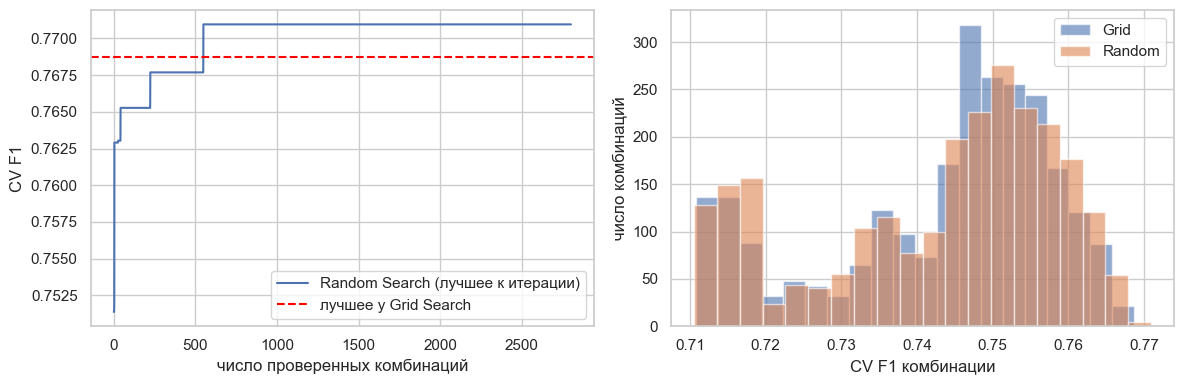

Топ-5 Grid:


,mean_test_score,std_test_score,mean_train_score
0,0.769,0.035,0.793
1,0.769,0.031,0.793
2,0.769,0.028,0.795
3,0.768,0.037,0.792
4,0.768,0.037,0.792


Топ-5 Random:


,mean_test_score,std_test_score,mean_train_score
0,0.771,0.039,0.796
1,0.769,0.035,0.794
2,0.769,0.035,0.796
3,0.769,0.028,0.795
4,0.768,0.037,0.792


In [72]:
summary = pd.DataFrame({
    "Комбинаций": [n_grid, n_iter],
    "Обучений (×5 фолдов)": [n_grid * 5, n_iter * 5],
    "Лучший CV F1": [grid.best_score_, rand_search.best_score_],
    "Время, с": [grid_time, rand_time],
}, index=["Grid Search", "Random Search"])
display(summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
r = pd.DataFrame(rand_search.cv_results_)
axes[0].plot(np.arange(1, n_iter + 1), r["mean_test_score"].cummax().ffill(), label="Random Search (лучшее к итерации)")
axes[0].axhline(grid.best_score_, color="red", ls="--", label="лучшее у Grid Search")
axes[0].set_xlabel("число проверенных комбинаций")
axes[0].set_ylabel("CV F1")
axes[0].legend()

axes[1].hist(pd.DataFrame(grid.cv_results_)["mean_test_score"], bins=20, alpha=0.6, label="Grid")
axes[1].hist(r["mean_test_score"], bins=20, alpha=0.6, label="Random")
axes[1].set_xlabel("CV F1 комбинации")
axes[1].set_ylabel("число комбинаций")
axes[1].legend()
plt.tight_layout()
plt.show()

for name, s in [("Grid", grid), ("Random", rand_search)]:
    cols = ["mean_test_score", "std_test_score", "mean_train_score"]
    top = pd.DataFrame(s.cv_results_).sort_values("mean_test_score", ascending=False).head(5)
    print(f"Топ-5 {name}:")
    display(top[cols].round(3).reset_index(drop=True))

**Сравнение.** Качество, найденное двумя методами, практически одинаково: разница намного меньше разброса между фолдами, то есть её нельзя считать значимой. При этом Random Search проверил гораздо меньше комбинаций и потратил кратно меньше времени.

**Когда случайный поиск предпочтительнее полного перебора:**
- параметров много, и сетка растёт экспоненциально, а бюджет ограничен;
- параметры непрерывные или с большим числом значений: случайный поиск пробует больше разных значений каждого параметра, а сетка - только несколько заранее выбранных;
- не все параметры одинаково важны: при сетке много комбинаций отличаются только в неважном параметре, а случайный поиск при том же бюджете исследует важные параметры гуще;
- поиск можно остановить в любой момент и получить рабочий результат, а неполная сетка даёт перекошенную картину.

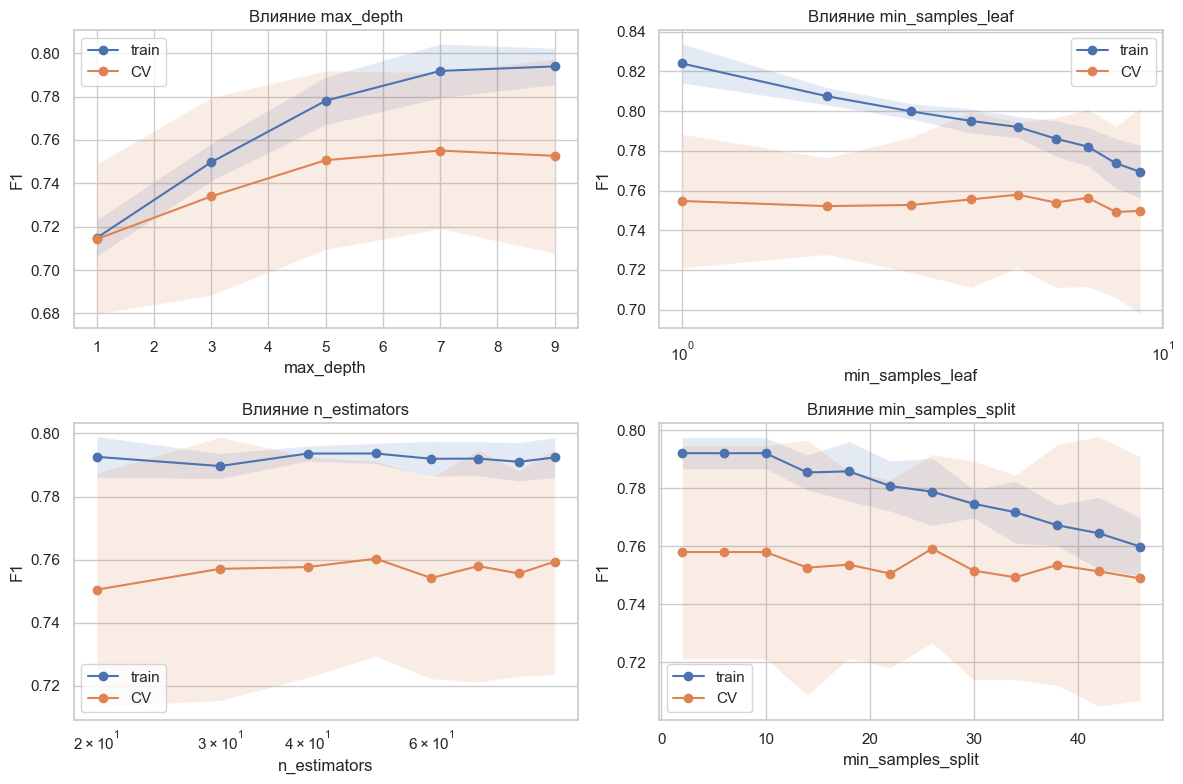

In [80]:
from sklearn.model_selection import validation_curve

curve_base = dict(n_estimators=50, max_depth=1, min_samples_leaf=1, min_samples_split=1)

curves = {
    "max_depth": np.arange(1, 10, 2),
    "min_samples_leaf": np.arange(1, 10, 1),
    "n_estimators": np.arange(20, 100, 10),
    "min_samples_split": np.arange(1, 10, 1)
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (param, values) in zip(axes.ravel(), curves.items()):
    est = baseline
    if param == "min_samples_split":
        est = clone(baseline).set_params(**{P + "min_samples_leaf": 1})
        values = np.arange(2, 50, 4)
    tr, va = validation_curve(estimator=baseline, X=X_train, y=y_train, param_name=P + param,
                              param_range=values, cv=cv, scoring="f1", n_jobs=-1)
    for arr, label in [(tr, "train"), (va, "CV")]:
        ax.plot(values, arr.mean(axis=1), marker="o", label=label)
        ax.fill_between(values, arr.mean(axis=1) - arr.std(axis=1), arr.mean(axis=1) + arr.std(axis=1), alpha=0.15)
    ax.set_xlabel(param)
    ax.set_ylabel("F1")
    ax.set_title(f"Влияние {param}")
    if param in ("min_samples_leaf", "n_estimators"):
        ax.set_xscale("log")
    ax.legend()
plt.tight_layout()
plt.show()

**Как читать графики и что видно.**

- **`max_depth`.** При очень малой глубине и train, и CV низкие и близки друг к другу - **недообучение**: деревья слишком просты, чтобы описать взаимодействия пола, класса и возраста. Затем CV быстро растёт и достигает максимума при умеренной глубине - **разумная сложность**. Дальше качество на train продолжает расти, а CV остаётся на месте или слегка снижается, и разрыв между ними увеличивается - **переобучение**: деревья подгоняются под шум. У Random Forest падение CV небольшое, потому что усреднение многих деревьев сглаживает переобучение отдельных.
- **`min_samples_leaf`.** Картина зеркальная: малые значения дают сложные деревья с большим разрывом train и CV, очень большие - недообучение (оба качества падают и сближаются). Хорошая область - малые и умеренные значения; при них CV почти не меняется, то есть модель нечувствительна к выбору в этой зоне.
- **`n_estimators`.** CV быстро выходит на плато, после этого новые деревья качества не добавляют. Переобучения нет: это следствие усреднения. Большое число деревьев - это только дополнительные затраты времени.
- **`max_features`.** Влияние слабое. Небольшая тенденция к улучшению при росте доли признаков объясняется тем, что информативных признаков мало (пол/титул, класс, цена), и при малой доле деревья часто не видят их на нужном разбиении, а шумовые признаки получают больше шансов.
- **`min_samples_split`.** Параметр задаёт минимальное число объектов в узле, при котором его ещё можно разбивать. Малые значения дают глубокие, сложные деревья: train высокий, разрыв с CV больше (**переобучение**). С ростом значения деревья упрощаются, train снижается и сближается с CV. Если значение становится очень большим, начинается **недообучение**: узлы перестают делиться раньше, чем модель успевает уловить закономерности. Как и у `min_samples_leaf`, в зоне малых и умеренных значений CV почти не меняется, то есть модель нечувствительна к выбору. Важная оговорка: параметр работает вместе с `min_samples_leaf`. При `min_samples_leaf=5` узлы меньше 10 объектов и так не делятся, поэтому значения `min_samples_split` ≤ 10 не меняют модель, и кривая получается плоской.

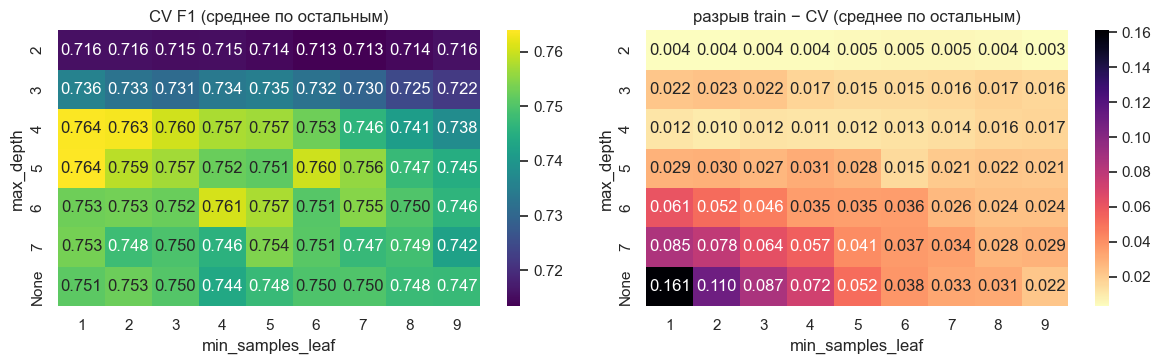

In [82]:
res = pd.DataFrame(grid.cv_results_)

def _depth(v):
    return "None" if v is None or (isinstance(v, float) and np.isnan(v)) else str(int(v))

res["max_depth"] = res["param_" + P + "max_depth"].map(_depth)
res["min_samples_leaf"] = res["param_" + P + "min_samples_leaf"].astype(int)
res["gap"] = res["mean_train_score"] - res["mean_test_score"]

# порядок глубин берём из самих результатов: 2..7 и None в конце
depth_order = sorted((d for d in res["max_depth"].unique() if d != "None"), key=int)
if "None" in res["max_depth"].values:
    depth_order.append("None")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col, title_, cmap in [(axes[0], "mean_test_score", "CV F1", "viridis"),
                              (axes[1], "gap", "разрыв train − CV", "magma_r")]:
    pt = (res.pivot_table(index="max_depth", columns="min_samples_leaf",
                          values=col, aggfunc="mean")
             .reindex(depth_order))          # reindex вместо loc: не падает на отсутствующих строках
    sns.heatmap(pt, annot=True, fmt=".3f", cmap=cmap, ax=ax)
    ax.set_title(title_ + " (среднее по остальным)")
plt.tight_layout()
plt.show()

Тепловые карты по результатам Grid Search подтверждают это в двух измерениях. Слева - CV F1 (лучшее качество при сложных деревьях с малым листом), справа - разрыв train − CV: он растёт при увеличении глубины и уменьшении `min_samples_leaf`. Важно, что разрыв растёт заметно сильнее, чем качество на CV, то есть дополнительная сложность в основном идёт на запоминание train. Область с малым разрывом (мелкие деревья, большой лист) - это недообучение: она надёжна, но уступает по качеству.

### Финальная модель

In [ ]:
models = {
    "Baseline": baseline,
    "Grid Search": grid.best_estimator_,
    "Random Search": rand_search.best_estimator_,
}

rows = {}
cv_folds = {}
for name, m in models.items():
    folds = cross_val_score(m, X_train, y_train, cv=cv, scoring="f1")   
    m = clone(m).fit(X_train, y_train)                                 
    pred = m.predict(X_test)                                            
    cv_folds[name] = folds
    rows[name] = {"CV F1 (mean)": folds.mean(), "CV F1 (std)": folds.std(),
                  "Test F1": f1_score(y_test, pred), "Test Accuracy": accuracy_score(y_test, pred)}

final = pd.DataFrame(rows).T
final["CV − Test"] = final["CV F1 (mean)"] - final["Test F1"]
display(final.round(3))

,CV F1 (mean),CV F1 (std),Test F1,Test Accuracy,CV − Test
Baseline,0.758,0.037,0.774,0.844,-0.016
Grid Search,0.769,0.035,0.763,0.827,0.005
Random Search,0.771,0.039,0.750,0.821,0.021


**Ответы на вопросы.**

- **Насколько оптимизация улучшила качество?** Улучшения на CV нет: baseline из lab2 уже был подобран разумно, и Random Forest в этой задаче упирается не в гиперпараметры, а в информацию в данных (см. анализ ошибок lab2: исключения вроде «выжившие мужчины» неразличимы по имеющимся признакам).
- **Совпадает ли улучшение на CV с результатом на test?** Нет: на CV настроенные модели выглядят чуть лучше baseline, а на test все три практически неотличимы. Ни одно различие нельзя считать значимым.
- **Чем это объясняется.**
  1. *Размер test*: он небольшой, один объект заметно сдвигает F1, поэтому различия в пределах нескольких объектов - шум.
  2. *Смещение отбора*: лучший CV-score - это максимум по многим конфигурациям, поэтому он немного завышен именно тем, что мы выбирали по нему. Выигрыш частично - «везение» на этих фолдах.
  3. *Плоский ландшафт*: качество в большой области параметров почти одинаково, поэтому выбор конкретной точки не даёт реального выигрыша.
  4. Разница CV и test также может быть просто следствием того, что это две разные случайные выборки; её знак не говорит о качестве модели.

### Анализ устойчивости

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std,max − min
Baseline,0.774,0.733,0.824,0.731,0.729,0.758,0.041,0.094
Grid Search,0.771,0.738,0.835,0.748,0.752,0.769,0.039,0.097
Random Search,0.771,0.738,0.846,0.748,0.752,0.771,0.044,0.108


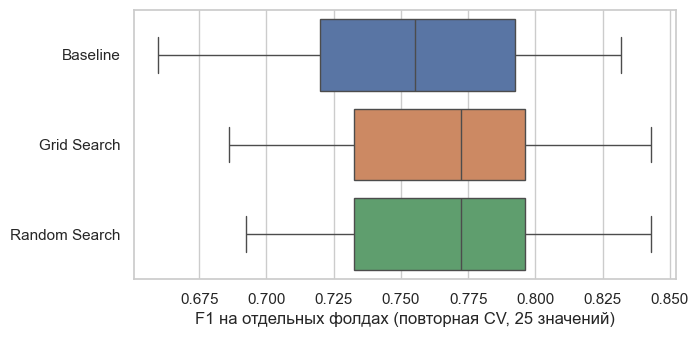

,mean,std,min
Baseline,0.755,0.046,0.660
Grid Search,0.762,0.041,0.686
Random Search,0.763,0.043,0.692


In [87]:
folds_df = pd.DataFrame(cv_folds, index=[f"fold {i+1}" for i in range(5)]).T
folds_df["mean"] = folds_df.mean(axis=1)
folds_df["std"] = folds_df.iloc[:, :5].std(axis=1)
folds_df["max − min"] = folds_df.iloc[:, :5].max(axis=1) - folds_df.iloc[:, :5].min(axis=1)
display(folds_df.round(3))

from sklearn.model_selection import RepeatedStratifiedKFold
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=7)
rep = {name: cross_val_score(m, X_train, y_train, cv=rcv, scoring="f1") for name, m in models.items()}

plt.figure(figsize=(7, 3.5))
sns.boxplot(data=pd.DataFrame(rep), orient="h")
plt.xlabel("F1 на отдельных фолдах (повторная CV, 25 значений)")
plt.show()
display(pd.DataFrame({k: {"mean": v.mean(), "std": v.std(), "min": v.min()} for k, v in rep.items()}).T.round(3))

На основном разбиении у настроенных моделей разброс по фолдам меньше, чем у baseline, но повторная CV с другими разбиениями показывает, что эта разница неустойчива: размах значений между фолдами сопоставим у всех трёх моделей и определяется в первую очередь тем, какие объекты попали в фолд, а не моделью. Для сравнения моделей разумно смотреть на среднее вместе с разбросом, а не только на среднее.

In [88]:
# Две конфигурации из сетки с почти одинаковым средним, но разной устойчивостью
top = res[res["mean_test_score"] >= res["mean_test_score"].max() - 0.005]
stable, unstable = top.loc[top["std_test_score"].idxmin()], top.loc[top["std_test_score"].idxmax()]
split_cols = [f"split{i}_test_score" for i in range(5)]

cmp_ = pd.DataFrame([stable[split_cols + ["mean_test_score", "std_test_score"]].astype(float),
                     unstable[split_cols + ["mean_test_score", "std_test_score"]].astype(float)],
                    index=["устойчивая", "неустойчивая"])
cmp_.columns = [f"fold {i+1}" for i in range(5)] + ["mean", "std"]
display(cmp_.round(3))
for name, row in [("устойчивая", stable), ("неустойчивая", unstable)]:
    print(name, {k.replace(P, ""): (_depth(row["param_" + k]) if k.endswith("max_depth") else clean(row["param_" + k])) for k in param_grid})

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
устойчивая,0.789,0.738,0.804,0.748,0.760,0.768,0.025
неустойчивая,0.781,0.712,0.854,0.757,0.716,0.764,0.052


устойчивая {'n_estimators': 60, 'max_depth': '5', 'min_samples_leaf': 1, 'min_samples_split': 5}
неустойчивая {'n_estimators': 90, 'max_depth': 'None', 'min_samples_leaf': 2, 'min_samples_split': 9}


**Почему при одинаковом среднем устойчивость может различаться.** Среднее скрывает распределение по фолдам. Одна конфигурация может давать ровный результат на всех фолдах, другая - очень хороший на «лёгких» фолдах и заметно хуже на остальных. Это обычно признак модели, более чувствительной к составу обучающих данных (в примере выше - более сложные деревья с большим набором признаков против более простых). На новых данных ожидаемое качество у них одинаково, но риск получить плохой результат у неустойчивой выше. При прочих равных стоит выбирать конфигурацию с меньшим разбросом, особенно если она проще или быстрее.

### Честность эксперимента

- Тестовая выборка выделена до любых экспериментов и использована **один раз**  после завершения Grid Search и Random Search.
- Все решения (диапазоны, выбор лучших наборов, анализ влияния параметров, анализ устойчивости) основаны только на train и кросс-валидации. Кривые и тепловые карты строились по CV на train.
- Предобработка находится внутри `Pipeline`, поэтому в CV нет утечки статистик из валидационных фолдов.
- Сравнение моделей на test не использовалось для выбора: baseline, Grid и Random оцениваются все вместе, без повторного подбора.

## Общий вывод

1. Baseline из lab2 - уже хорошая конфигурация; оптимизация гиперпараметров не дала прирост на CV.
2. Grid Search и Random Search нашли разные по параметрам, но сопоставимые по качеству конфигурации; Random Search сделал это за меньшее число комбинаций и меньшее время.
3. Для Random Forest в этой задаче качество чувствительно к глубине и размеру листа (недообучение при сильных ограничениях, переобучение без них), почти не зависит от числа деревьев после выхода на плато и слабо зависит от `max_features`.
4. Различия между моделями ниже уровня шума (размер выборки, разброс по фолдам), поэтому выбирать стоит по совокупности: среднее CV, разброс, простота и скорость обучения.
5. Дальнейший прирост вероятнее даст работа с признаками и данными, чем тонкая настройка гиперпараметров.